# [NII] BPT Diagram for DESI DR1

Ragadeepika Pucha, Stéphanie Juneau, Mar Mezcua, Arjun Dey, Yao-Yuan Mao, and others ...

This Notebook uses the [NII]-BPT Diagram to identify AGN in galaxies. <br/>

In [1]:
import numpy as np

from astropy.table import Table, join, Column

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')

import bpt
import utils

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from scipy.ndimage import gaussian_filter

from desitarget.targetmask import desi_mask
from desitarget.sv1.sv1_targetmask import desi_mask as sv1_desi_mask
from desitarget.sv2.sv2_targetmask import desi_mask as sv2_desi_mask
from desitarget.sv3.sv3_targetmask import desi_mask as sv3_desi_mask

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':20,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':2.0,
    'xtick.major.size':6.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':2.0,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':6.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':2.0,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
t = Table.read('../catalogs/iron-selection-v2.3.fits')
len(t)

6099572

In [4]:
## Stellar Mass related variables

logmass = t['LOGM'].data
lomass = (logmass <= 9.5)
himass = (logmass > 9.5)

len(t[lomass]), len(t[himass])

(987987, 5111585)

In [5]:
## BL Related Variables

z = t['Z'].data
ha_b = t['HA_B_FLUX'].data
ha_b_snr = ha_b/t['HA_B_FLUX_ERR'].data
ha_b_aon = t['HA_B_AMPLITUDE'].data/t['NII_HA_NOISE'].data
ha_b_sig = t['HA_B_SIGMA'].data
ha_b_sig_snr = ha_b_sig/t['HA_B_SIGMA_ERR'].data
per_broad = t['PROB_BROAD'].data

ha_b_lum = utils.Flux_to_Luminosity(ha_b*1e-17, z)
ha_b_fwhm = utils.sigma_to_fwhm(ha_b_sig)
bh_mass = utils.calculate_bh_masses(ha_b_lum, ha_b_fwhm)

In [6]:
## Number of two-component fits

is_sii_out = (t['SII6716_OUT_FLUX'].data != 0)
is_oiii_out = (t['OIII5007_OUT_FLUX'].data != 0)

print ('Number of sources with an extra [SII] component: ', len(t[is_sii_out]), round(len(t[is_sii_out])*100/len(t), 1), '%')
print ('Number of sources with an extra [OIII] component: ', len(t[is_oiii_out]), round(len(t[is_oiii_out])*100/len(t), 1), '%')

Number of sources with an extra [SII] component:  35666 0.6 %
Number of sources with an extra [OIII] component:  71618 1.2 %


In [7]:
## Double-Peaked Emission Line Flags
is_sii_dbl = t['SII_DBL_FLAG'].data
is_oiii_dbl = t['OIII_DBL_FLAG'].data

len(t[is_sii_dbl]), len(t[is_oiii_dbl])

(24735, 15702)

In [8]:
## Emission-line measurements -- Narrow only and sum

## Narrow Only
nii_n = t['NII6583_FLUX'].data
nii_snr_n = nii_n/t['NII6583_FLUX_ERR'].data
nii_aon = t['NII6583_AMPLITUDE'].data/t['NII_HA_NOISE'].data

oiii_n = t['OIII5007_FLUX'].data
oiii_snr_n = oiii_n/t['OIII5007_FLUX_ERR'].data
oiii_aon = t['OIII5007_AMPLITUDE'].data/t['OIII_NOISE'].data

ha_n = t['HA_N_FLUX'].data
ha_snr_n = ha_n/t['HA_N_FLUX_ERR'].data
ha_aon = t['HA_N_AMPLITUDE'].data/t['NII_HA_NOISE'].data

hb_n = t['HB_N_FLUX'].data
hb_snr_n = hb_n/t['HB_N_FLUX_ERR'].data
hb_aon = t['HB_N_AMPLITUDE'].data/t['HB_NOISE']


## Sum
nii_sum = t['NII6583_FLUX'].data + t['NII6583_OUT_FLUX'].data
nii_snr_sum = nii_sum/np.sqrt((t['NII6583_FLUX_ERR'].data**2) + (t['NII6583_OUT_FLUX_ERR'].data**2))

oiii_sum = t['OIII5007_FLUX'].data + t['OIII5007_OUT_FLUX'].data
oiii_snr_sum = oiii_sum/np.sqrt((t['OIII5007_FLUX_ERR'].data**2) + (t['OIII5007_OUT_FLUX_ERR'].data**2))

ha_sum = t['HA_N_FLUX'].data + t['HA_OUT_FLUX'].data
ha_snr_sum = ha_sum/np.sqrt((t['HA_N_FLUX_ERR'].data**2) + (t['HA_OUT_FLUX_ERR'].data**2))

hb_sum = t['HB_N_FLUX'].data + t['HB_OUT_FLUX'].data
hb_snr_sum = hb_sum/np.sqrt((t['HB_N_FLUX_ERR'].data**2) + (t['HB_OUT_FLUX_ERR'].data**2))

In [9]:
## Emission-line measurements

## Empty arrays
nii, nii_snr = np.zeros(len(t)), np.zeros(len(t))
oiii, oiii_snr = np.zeros(len(t)), np.zeros(len(t))
ha, ha_snr = np.zeros(len(t)), np.zeros(len(t))
hb, hb_snr = np.zeros(len(t)), np.zeros(len(t))

## [OIII] Condition
oiii[is_oiii_dbl], oiii[~is_oiii_dbl] = oiii_sum[is_oiii_dbl], oiii_n[~is_oiii_dbl]
oiii_snr[is_oiii_dbl], oiii_snr[~is_oiii_dbl] = oiii_snr_sum[is_oiii_dbl], oiii_snr_n[~is_oiii_dbl]

## [NII]+Ha Condition
nii[is_sii_dbl], nii[~is_sii_dbl] = nii_sum[is_sii_dbl], nii_n[~is_sii_dbl]
nii_snr[is_sii_dbl], nii_snr[~is_sii_dbl] = nii_snr_sum[is_sii_dbl], nii_snr_n[~is_sii_dbl]

ha[is_sii_dbl], ha[~is_sii_dbl] = ha_sum[is_sii_dbl], ha_n[~is_sii_dbl]
ha_snr[is_sii_dbl], ha_snr[~is_sii_dbl] = ha_snr_sum[is_sii_dbl], ha_snr_n[~is_sii_dbl]

hb[is_sii_dbl], hb[~is_sii_dbl] = hb_sum[is_sii_dbl], hb_n[~is_sii_dbl]
hb_snr[is_sii_dbl], hb_snr[~is_sii_dbl] = hb_snr_sum[is_sii_dbl], hb_snr_n[~is_sii_dbl]

nii_ha = np.log10(nii/ha)
oiii_hb = np.log10(oiii/hb)

In [10]:
is_agn, is_comp, is_sf = bpt.Classify_NII_BPT(nii_ha, oiii_hb)

In [11]:
## Cuts
bpt_cut = (nii_snr >= 3)&(oiii_snr >= 3)&(ha_snr >= 3)&(hb_snr >= 1)&(hb_aon >= 1)
bl_cut = (ha_b_fwhm >= 300)&(ha_b_fwhm < 15000)&(ha_b_snr >= 3)&(ha_b_sig_snr >= 3)&(ha_b_aon >= 2)&(per_broad >= 80)&(t['HA_B_SIGMA'].data > t['HA_N_SIGMA'].data)&(t['HA_N_AMPLITUDE'].data > t['HA_B_AMPLITUDE'].data)

is_bl = bpt_cut&bl_cut
is_nl = bpt_cut&~bl_cut

In [12]:
print ('Number of High-mass Line-Emitting Galaxies: ', len(t[bpt_cut&lomass]))
print ('Number of Dwarf Line-Emitting Galaxies: ', len(t[bpt_cut&himass]))

Number of High-mass Line-Emitting Galaxies:  467214
Number of Dwarf Line-Emitting Galaxies:  1211573


In [13]:
print ('Number of Line-Emitting Galaxies with Non-zero broad Ha flux: ', len(t[bpt_cut&(ha_b != 0)]))

Number of Line-Emitting Galaxies with Non-zero broad Ha flux:  57007


In [14]:
print ('Total Number of Line-Emitting galaxies:', len(t[bpt_cut]), f'({round(len(t[bpt_cut])*100/len(t), 1)}%)')
print ('Total Number of NL Candidates:', len(t[is_nl]))
print ('Number of High-Mass NL Candidates:', len(t[is_nl&himass]))
print ('Number of Dwarf NL Candidates:', len(t[is_nl&lomass]))
print ('Total Number of BL Candidates:', len(t[is_bl]))
print ('Number of High-Mass BL Candidates:', len(t[is_bl&himass]))
print ('Number of Dwarf BL Candidates:', len(t[is_bl&lomass]))

Total Number of Line-Emitting galaxies: 1678787 (27.5%)
Total Number of NL Candidates: 1652199
Number of High-Mass NL Candidates: 1188231
Number of Dwarf NL Candidates: 463968
Total Number of BL Candidates: 26588
Number of High-Mass BL Candidates: 23342
Number of Dwarf BL Candidates: 3246


Text(0, 0.5, '$\\log~(M_{\\star}/M_{\\odot})$')

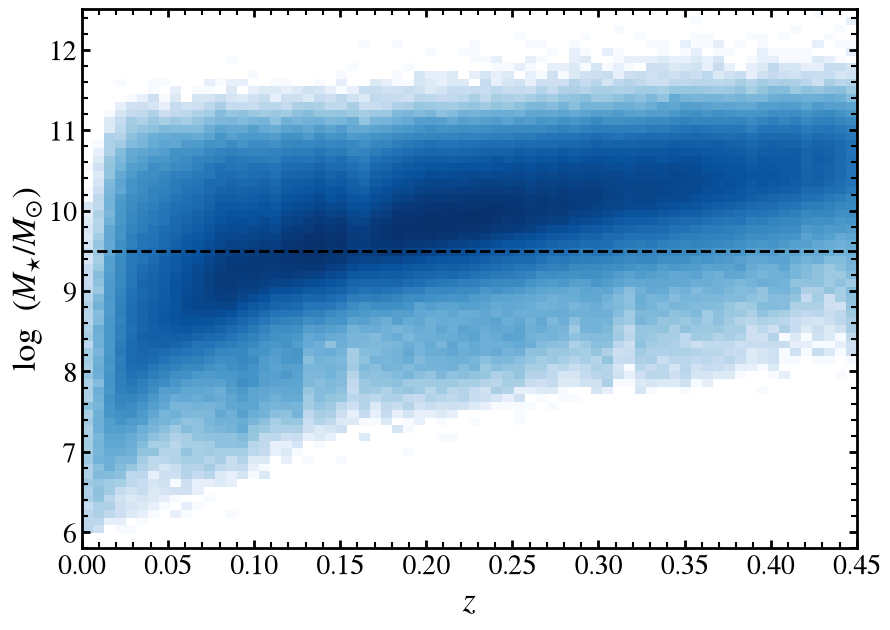

In [15]:
plt.figure(figsize = (10, 7))

hist1 = plt.hist2d(z[bpt_cut], logmass[bpt_cut], bins = 70, norm = LogNorm(), range = [[0, 0.45], [5.8, 12.5]], cmap = 'Blues')
plt.axhline(9.5, color = 'k', lw = 2.0, ls = '--')
plt.xlabel('$z$')
plt.ylabel('$\log~(M_{\star}/M_{\odot})$')

# plt.savefig('mstar_z_2dhist.png')

In [16]:
def get_data_hist2d(h2d):
    xx = np.array([])
    yy = np.array([])
    nn = np.array([])
    
    for ii in range(len(h2d[1])-1):
        for jj in range(len(h2d[2])-1):
            xx = np.append(xx, h2d[1][ii])
            yy = np.append(yy, h2d[2][jj])
            nn = np.append(nn, h2d[0][ii][jj])
            
    return (xx, yy, nn)

In [17]:
## Save the M*-z figure data

# xx1, yy1, nn1 = get_data_hist2d(hist1)
# t1 = Table()
# t1['z'] = xx1
# t1['logmass'] = yy1
# t1.add_column(Column(nn1, name = 'NUM', dtype = np.int))
# t1.write('../catalogs/paper_figures/Fig01.csv', format = 'csv', overwrite = True)

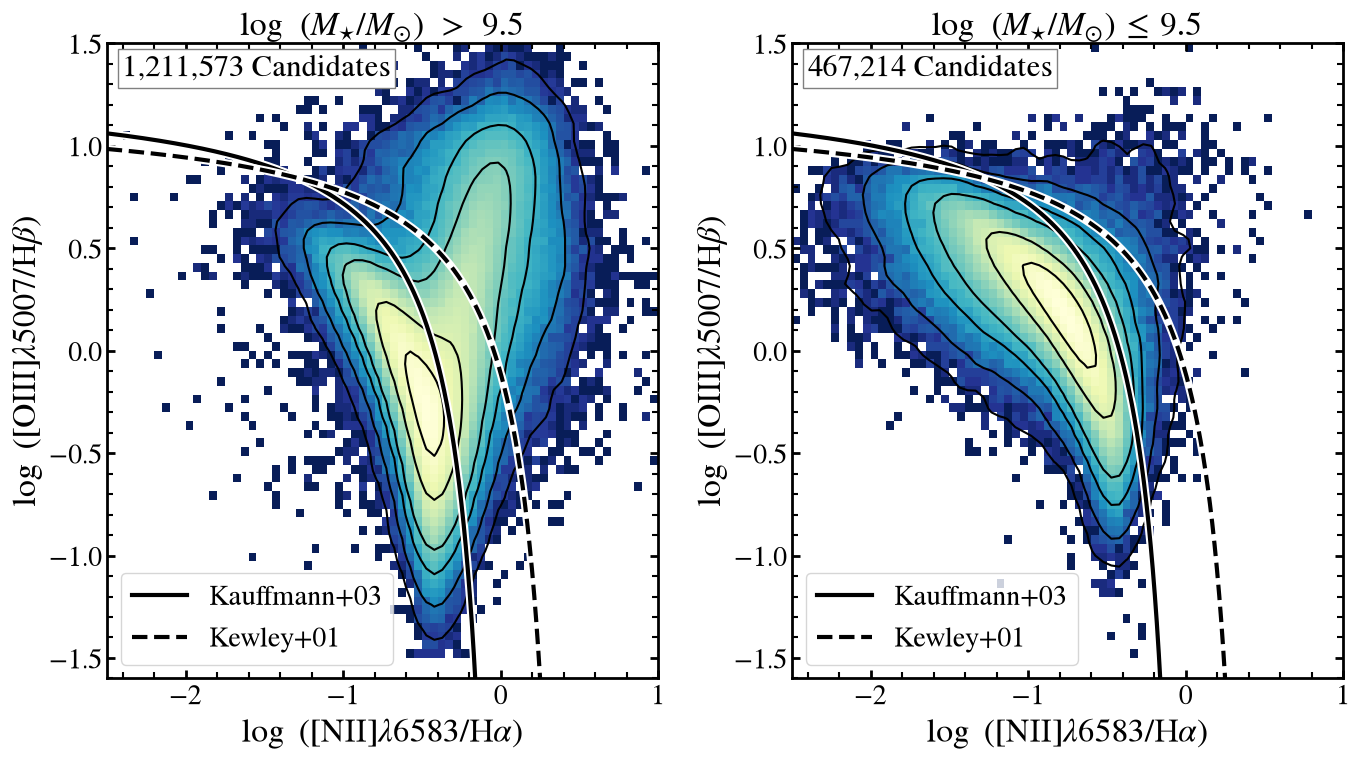

In [18]:
## Plot contours of BPT diagram for massive and dwarf galaxies
dens_lomass, _, _ = np.histogram2d(nii_ha[bpt_cut&lomass], oiii_hb[bpt_cut&lomass], bins = 70, range = [[-2.5, 1], [-1.5, 1.5]], density = True)
dens_himass, _, _ = np.histogram2d(nii_ha[bpt_cut&himass], oiii_hb[bpt_cut&himass], bins = 70, range = [[-2.5, 1], [-1.5, 1.5]], density = True)

# Apply Gaussian filter to smooth the density arrays
dens_himass_smooth = gaussian_filter(dens_himass, sigma=1)
dens_lomass_smooth = gaussian_filter(dens_lomass, sigma=1)

plt.figure(figsize = (14, 8))

plt.subplot2grid((1,2), (0,0))
plt.title('$\log~(M_{\star}/M_{\odot})~>~9.5$', fontsize = 24)
h1 = plt.hist2d(nii_ha[bpt_cut&himass], oiii_hb[bpt_cut&himass], bins = 70, norm = LogNorm(), range = [[-2.5, 1], [-1.5, 1.5]], cmap = 'YlGnBu_r')
# plt.colorbar(label = '# of Sources')
bpt.Plot_NII_BPT_Lines(Schawinsky = False, legend = True)
plt.contour(dens_himass_smooth.T, levels=[0.002, 0.01, 0.05, 0.15, 1.0, 3, 5], extent=[-2.5, 1, -1.5, 1.5], colors='k', linewidths=1.5, zorder=1)
plt.text(-2.4, 1.34, f'{len(nii_ha[bpt_cut&himass]):,} Candidates', fontsize = 22, bbox = dict(facecolor = 'white', edgecolor = 'grey', pad = 3))
plt.xlabel('$\log$ ([NII]$\lambda$6583/H$\\alpha$)')
plt.ylabel('$\log$ ([OIII]$\lambda$5007/H$\\beta$)')

plt.subplot2grid((1,2), (0,1))
plt.title('$\log~(M_{\star}/M_{\odot})~≤~9.5$', fontsize = 24)
h2 = plt.hist2d(nii_ha[bpt_cut&lomass], oiii_hb[bpt_cut&lomass], bins = 70, norm = LogNorm(), range = [[-2.5, 1], [-1.5, 1.5]], cmap = 'YlGnBu_r')
# plt.colorbar(label = '# of Sources')
plt.contour(dens_lomass_smooth.T, levels=[0.002, 0.01, 0.05, 0.15,  1.0, 3], extent=[-2.5, 1, -1.5, 1.5], colors='k', linewidths=1.5, zorder=1)
bpt.Plot_NII_BPT_Lines(Schawinsky = False, legend = True)
plt.text(-2.4, 1.34, f'{len(nii_ha[bpt_cut&lomass]):,} Candidates', fontsize = 22, bbox = dict(facecolor = 'white', edgecolor = 'grey', pad = 3))
plt.xlabel('$\log$ ([NII]$\lambda$6583/H$\\alpha$)')
plt.ylabel('$\log$ ([OIII]$\lambda$5007/H$\\beta$)')

plt.tight_layout()

# plt.savefig('bpt_all_2panel.png')

In [19]:
## Save the BPT Figure
# xx1, yy1, nn1 = get_data_hist2d(h1)
# xx2, yy2, nn2 = get_data_hist2d(h2)

# t1 = Table()
# t1['log_nii_ha'] = xx1
# t1['log_oiii_hb'] = yy1
# t1.add_column(Column(nn1, name = 'NUM', dtype = np.int))
# t1.write('../catalogs/paper_figures/Fig02a_highmass.csv', format = 'csv', overwrite = True)

# t2 = Table()
# t2['log_nii_ha'] = xx2
# t2['log_oiii_hb'] = yy2
# t2.add_column(Column(nn2, name = 'NUM', dtype = np.int))
# t2.write('../catalogs/paper_figures/Fig02b_lowmass.csv', format = 'csv', overwrite = True)

### Comparison with SDSS and GAMA Surveys

In [20]:
t_r13_1 = Table.read('../../../02_Completed_Projects/01_Pucha_2025/catalogs/other_cats/reines2013_table1.txt', format = 'ascii')
t_r13_2 = Table.read('../../../02_Completed_Projects/01_Pucha_2025/catalogs/other_cats/reines2013_table2.txt', format = 'ascii')
t_r13 = join(t_r13_1, t_r13_2, keys = ['ID'])

t_gama = Table.read('../../../02_Completed_Projects/01_Pucha_2025/catalogs/other_cats/gama_dwarf_agn.fits')
t_gama = t_gama[(t_gama['logM'].data <= 9.5)&(t_gama['NIILoc'].astype(str) != 'SF')]

t_desi = t[(is_nl|is_bl)&(is_agn|is_comp)&lomass]

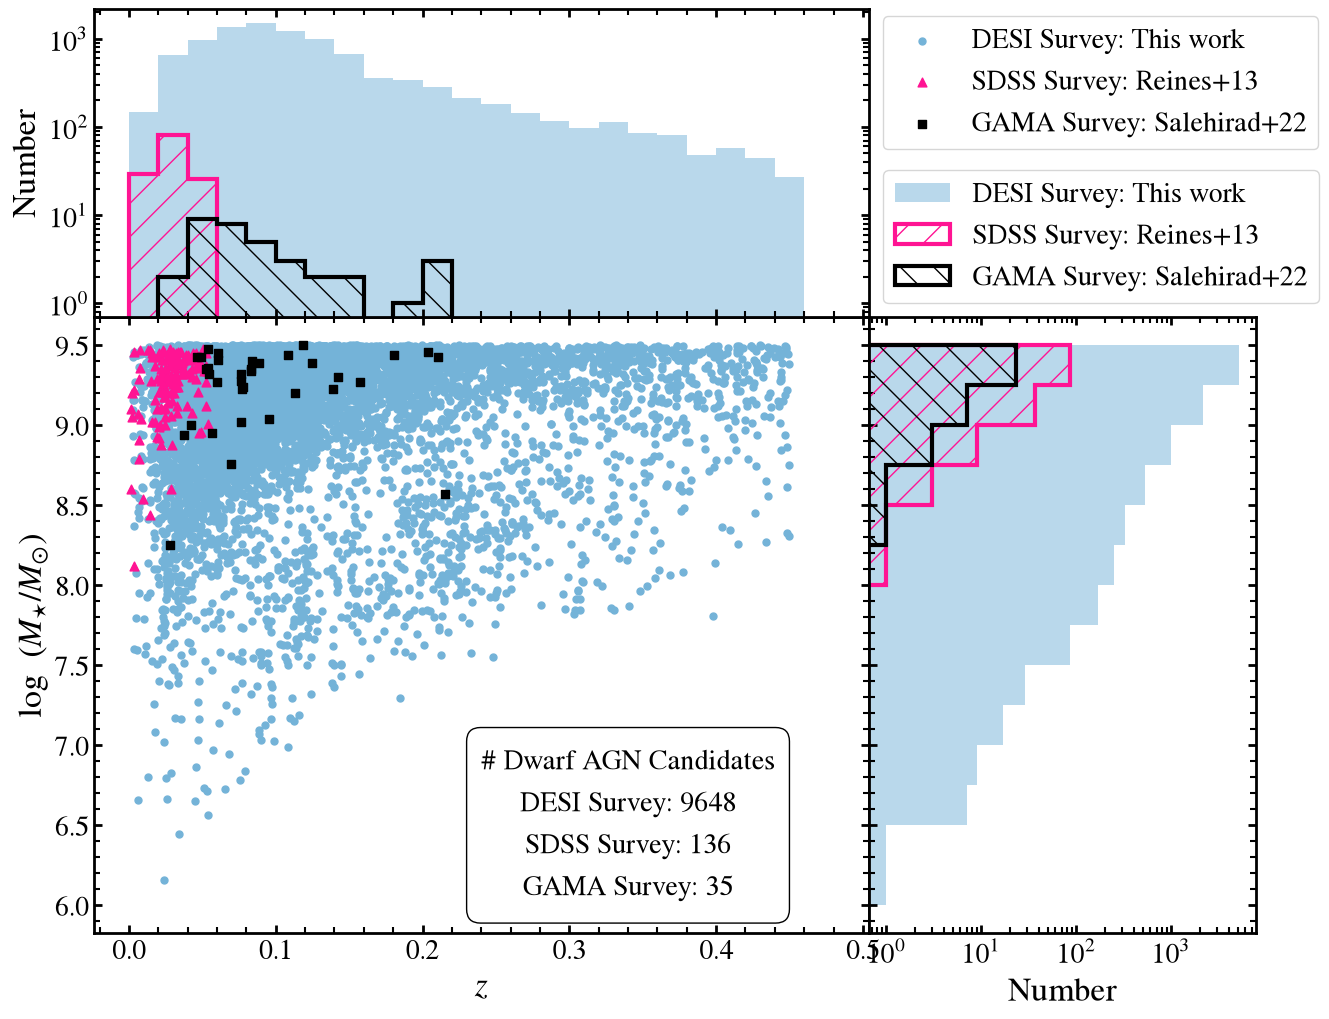

In [21]:
fig = plt.figure(figsize = (15, 12), constrained_layout = True)
grid = plt.GridSpec(6,6, hspace = 0.0, wspace = 0.0)
ax = fig.add_subplot(grid[2:, :-2])

x_hist = fig.add_subplot(grid[0:2,:-2], sharex = ax)
y_hist = fig.add_subplot(grid[2:,-2:], sharey = ax)

ax.scatter(t_desi['Z'].data, t_desi['LOGM'].data, s = 100, marker = '.', color = '#74b3d8', label = 'DESI Survey: This work')
ax.scatter(t_r13['z'].data, t_r13['mass'].data, s = 40, marker = '^', color = 'deeppink', label = 'SDSS Survey: Reines+13') # color = '#d55e00'
ax.scatter(t_gama['z'].data, t_gama['logM'].data, s = 30, marker = 's', color = 'k', label = 'GAMA Survey: Salehirad+22')
ax.set(ylabel = '$\log~(M_{\star}/M_{\odot})$', xlabel = '$z$')
leg1 = ax.legend(loc = 'lower left', fontsize = 20, frameon = True, bbox_to_anchor = (1.0, 1.25))
text_str = (
    '# Dwarf AGN Candidates\n'
    f'DESI Survey: {len(t_desi["Z"].data)}\n'
    f'SDSS Survey: {len(t_r13["z"].data)}\n'
    f'GAMA Survey: {len(t_gama["z"].data)}'
)

# Define text properties and bounding box properties
bbox_props = dict(boxstyle="round,pad=0.5", edgecolor="black", facecolor="none")

# Add multiline text with a bounding box, centered
ax.text(0.34, 6.5, text_str, bbox=bbox_props, fontsize=20, 
        ha='center', va='center')

zbins = np.arange(0, 0.5, 0.02)
z1 = x_hist.hist(t_desi['Z'], color = '#74b3d8', lw = 3.0, bins = zbins, histtype = 'bar', log = True, alpha = 0.5)
x_hist.hist(t_r13['z'], color = 'deeppink', lw = 3.0, bins = zbins, histtype = 'step', log = True, hatch = '/')
x_hist.hist(t_gama['z'], color = 'k' , lw = 3.0, bins = zbins, histtype = 'step', log = True, hatch = '\\')
x_hist.set(ylabel = 'Number')

mbins = np.arange(6, 9.75, 0.25)
m1 = y_hist.hist(t_desi['LOGM'].data, bins = mbins, color = '#74b3d8', lw = 3.0, histtype = 'bar', alpha = 0.5, log = True, orientation = 'horizontal', label = 'DESI Survey: This work')
y_hist.hist(t_r13['mass'], color = 'deeppink', lw = 3.0, bins = mbins, histtype = 'step', log = True, hatch = '/', orientation = 'horizontal', label = 'SDSS Survey: Reines+13')
y_hist.hist(t_gama['logM'], color = 'k', lw = 3.0, bins = mbins, histtype = 'step', log = True, hatch = '\\', orientation = 'horizontal', label = 'GAMA Survey: Salehirad+22')
y_hist.set(xlabel = 'Number')
leg = y_hist.legend(fontsize = 20, bbox_to_anchor = (0.002, 1.0))

plt.setp(x_hist.get_xticklabels(), visible = False)
plt.setp(y_hist.get_yticklabels(), visible = False)

plt.show()
# plt.savefig('Mstar_z_dr1.png', bbox_extra_artists = (leg1, leg), bbox_inches = 'tight', dpi=300)

### Numbers

In [22]:
is_leg = (is_nl|is_bl)

In [23]:
is_bgs = (t['DESI_TARGET'].data & desi_mask['BGS_ANY'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['BGS_ANY'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['BGS_ANY'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['BGS_ANY'] != 0))
is_mws = (t['DESI_TARGET'].data & desi_mask['MWS_ANY'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['MWS_ANY'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['MWS_ANY'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['MWS_ANY'] != 0))
is_lrg = (t['DESI_TARGET'].data & desi_mask['LRG'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['LRG'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['LRG'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['LRG'] != 0))
is_elg = (t['DESI_TARGET'].data & desi_mask['ELG'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['ELG'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['ELG'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['ELG'] != 0))
is_qso = (t['DESI_TARGET'].data & desi_mask['QSO'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['QSO'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['QSO'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['QSO'] != 0))
is_scnd = (t['DESI_TARGET'].data & desi_mask['SCND_ANY'] != 0)|(t['SV1_DESI_TARGET'].data & sv1_desi_mask['SCND_ANY'] != 0)|\
(t['SV2_DESI_TARGET'].data & sv2_desi_mask['SCND_ANY'] != 0)|((t['SV3_DESI_TARGET'].data & sv3_desi_mask['SCND_ANY'] != 0))

In [24]:
print ('Total Number of LEGs:', len(t[is_leg]))
print ('Number of BGS LEGs:', len(t[is_bgs&is_leg]), f'({round(len(t[is_bgs&is_leg])*100/len(t[is_leg]), 1)}%)')
print ('Number of LRG LEGs:', len(t[is_lrg&is_leg]), f'({round(len(t[is_lrg&is_leg])*100/len(t[is_leg]), 1)}%)')
print ('Number of ELG LEGs:', len(t[is_elg&is_leg]), f'({round(len(t[is_elg&is_leg])*100/len(t[is_leg]), 1)}%)')
print ('Number of QSO LEGs:', len(t[is_qso&is_leg]), f'({round(len(t[is_qso&is_leg])*100/len(t[is_leg]), 1)}%)')
print ('Number of MWS LEGs:', len(t[is_mws&is_leg]), f'({round(len(t[is_mws&is_leg])*100/len(t[is_leg]), 1)}%)')
print ('Number of SCND LEGs:', len(t[is_scnd&is_leg]), f'({round(len(t[is_scnd&is_leg])*100/len(t[is_leg]), 1)}%)')
print ('------------------------------------------------------------------------------------')
print ('Total Number of High-Mass LEGs:', len(t[is_leg&himass]))
print ('Number of BGS High-Mass LEGs:', len(t[is_bgs&is_leg&himass]), f'({round(len(t[is_bgs&is_leg&himass])*100/len(t[is_leg&himass]), 1)}%)')
print ('Number of LRG High-Mass LEGs:', len(t[is_lrg&is_leg&himass]), f'({round(len(t[is_lrg&is_leg&himass])*100/len(t[is_leg&himass]), 1)}%)')
print ('Number of ELG High-Mass LEGs:', len(t[is_elg&is_leg&himass]), f'({round(len(t[is_elg&is_leg&himass])*100/len(t[is_leg&himass]), 1)}%)')
print ('Number of QSO High-Mass LEGs:', len(t[is_qso&is_leg&himass]), f'({round(len(t[is_qso&is_leg&himass])*100/len(t[is_leg&himass]), 1)}%)')
print ('Number of MWS High-Mass LEGs:', len(t[is_mws&is_leg&himass]), f'({round(len(t[is_mws&is_leg&himass])*100/len(t[is_leg&himass]), 1)}%)')
print ('Number of SCND High-Mass LEGs:', len(t[is_scnd&is_leg&himass]), f'({round(len(t[is_scnd&is_leg&himass])*100/len(t[is_leg&himass]), 1)}%)')
print ('------------------------------------------------------------------------------------')
print ('Total Number of Dwarf LEGs:', len(t[is_leg&lomass]))
print ('Number of BGS Dwarf LEGs:', len(t[is_bgs&is_leg&lomass]), f'({round(len(t[is_bgs&is_leg&lomass])*100/len(t[is_leg&lomass]), 1)}%)')
print ('Number of LRG Dwarf LEGs:', len(t[is_lrg&is_leg&lomass]), f'({round(len(t[is_lrg&is_leg&lomass])*100/len(t[is_leg&lomass]), 1)}%)')
print ('Number of ELG Dwarf LEGs:', len(t[is_elg&is_leg&lomass]), f'({round(len(t[is_elg&is_leg&lomass])*100/len(t[is_leg&lomass]), 1)}%)')
print ('Number of QSO Dwarf LEGs:', len(t[is_qso&is_leg&lomass]), f'({round(len(t[is_qso&is_leg&lomass])*100/len(t[is_leg&lomass]), 1)}%)')
print ('Number of MWS Dwarf LEGs:', len(t[is_mws&is_leg&lomass]), f'({round(len(t[is_mws&is_leg&lomass])*100/len(t[is_leg&lomass]), 1)}%)')
print ('Number of SCND Dwarf LEGs:', len(t[is_scnd&is_leg&lomass]), f'({round(len(t[is_scnd&is_leg&lomass])*100/len(t[is_leg&lomass]), 1)}%)')

Total Number of LEGs: 1678787
Number of BGS LEGs: 1553124 (92.5%)
Number of LRG LEGs: 43203 (2.6%)
Number of ELG LEGs: 19413 (1.2%)
Number of QSO LEGs: 21938 (1.3%)
Number of MWS LEGs: 2217 (0.1%)
Number of SCND LEGs: 293292 (17.5%)
------------------------------------------------------------------------------------
Total Number of High-Mass LEGs: 1211573
Number of BGS High-Mass LEGs: 1170374 (96.6%)
Number of LRG High-Mass LEGs: 42946 (3.5%)
Number of ELG High-Mass LEGs: 807 (0.1%)
Number of QSO High-Mass LEGs: 6895 (0.6%)
Number of MWS High-Mass LEGs: 2092 (0.2%)
Number of SCND High-Mass LEGs: 162065 (13.4%)
------------------------------------------------------------------------------------
Total Number of Dwarf LEGs: 467214
Number of BGS Dwarf LEGs: 382750 (81.9%)
Number of LRG Dwarf LEGs: 257 (0.1%)
Number of ELG Dwarf LEGs: 18606 (4.0%)
Number of QSO Dwarf LEGs: 15043 (3.2%)
Number of MWS Dwarf LEGs: 125 (0.0%)
Number of SCND Dwarf LEGs: 131227 (28.1%)


In [25]:
## Numbers

def print_nii_bpt_numbers(cut):
    print ('Total # of sources: ', len(t[cut]))
    print ('---------------------------------------------------------------')
    print ('Number of LEGs: ', len(t[cut&is_leg]))
    print ('Total Number of AGN: ', len(t[cut&is_agn&is_leg]), round(len(t[cut&is_agn&is_leg])*100/len(t[cut&is_leg]), 1), '%')
    print ('Total Number of Composites: ', len(t[cut&is_comp&is_leg]), round(len(t[cut&is_comp&is_leg])*100/len(t[cut&is_leg]), 1), '%')
    print ('Combined Number AGN+Composites: ', len(t[cut&(is_agn|is_comp)&is_leg]))
    print ('AGN Fraction: ', round(len(t[cut&(is_agn|is_comp)&is_leg])*100/len(t[cut&is_leg]), 1), '%')
    print ('Total Number of SF: ', len(t[cut&is_sf&is_leg]), round(len(t[cut&is_sf&is_leg])*100/len(t[cut&is_leg]), 1), '%')
    print ('---------------------------------------------------------------')
    print ('Number of NL LEGs: ', len(t[cut&is_nl]))
    print ('Total Number of NL-AGN: ', len(t[cut&is_agn&is_nl]), round(len(t[cut&is_agn&is_nl])*100/len(t[cut&is_nl]), 1), '%')
    print ('Total Number of NL-Composites: ', len(t[cut&is_comp&is_nl]), round(len(t[cut&is_comp&is_nl])*100/len(t[cut&is_nl]), 1), '%')
    print ('Combined Number NL-AGN+NL-Composites: ', len(t[cut&(is_agn|is_comp)&is_nl]))
    print ('Total Number of NL-SF: ', len(t[cut&is_sf&is_nl]), round(len(t[cut&is_sf&is_nl])*100/len(t[cut&is_nl]), 1), '%')
    print ('---------------------------------------------------------------')
    print ('Number of BL LEGs: ', len(t[cut&is_bl]))
    print ('Total Number of BL-AGN: ', len(t[cut&is_agn&is_bl]), round(len(t[cut&is_agn&is_bl])*100/len(t[cut&is_bl]), 1), '%')
    print ('Total Number of BL-Composites: ', len(t[cut&is_comp&is_bl]), round(len(t[cut&is_comp&is_bl])*100/len(t[cut&is_bl]), 1), '%')
    print ('Combined Number BL-AGN+BL-Composites: ', len(t[cut&(is_agn|is_comp)&is_bl]))
    print ('Total Number of BL-SF: ', len(t[cut&is_sf&is_bl]), round(len(t[cut&is_sf&is_bl])*100/len(t[cut&is_bl]), 1), '%')

In [26]:
print_nii_bpt_numbers(lomass)

Total # of sources:  987987
---------------------------------------------------------------
Number of LEGs:  467214
Total Number of AGN:  1675 0.4 %
Total Number of Composites:  7973 1.7 %
Combined Number AGN+Composites:  9648
AGN Fraction:  2.1 %
Total Number of SF:  457566 97.9 %
---------------------------------------------------------------
Number of NL LEGs:  463968
Total Number of NL-AGN:  1455 0.3 %
Total Number of NL-Composites:  7568 1.6 %
Combined Number NL-AGN+NL-Composites:  9023
Total Number of NL-SF:  454945 98.1 %
---------------------------------------------------------------
Number of BL LEGs:  3246
Total Number of BL-AGN:  220 6.8 %
Total Number of BL-Composites:  405 12.5 %
Combined Number BL-AGN+BL-Composites:  625
Total Number of BL-SF:  2621 80.7 %


In [27]:
print_nii_bpt_numbers(himass)

Total # of sources:  5111585
---------------------------------------------------------------
Number of LEGs:  1211573
Total Number of AGN:  106955 8.8 %
Total Number of Composites:  207290 17.1 %
Combined Number AGN+Composites:  314245
AGN Fraction:  25.9 %
Total Number of SF:  897328 74.1 %
---------------------------------------------------------------
Number of NL LEGs:  1188231
Total Number of NL-AGN:  94036 7.9 %
Total Number of NL-Composites:  201402 16.9 %
Combined Number NL-AGN+NL-Composites:  295438
Total Number of NL-SF:  892793 75.1 %
---------------------------------------------------------------
Number of BL LEGs:  23342
Total Number of BL-AGN:  12919 55.3 %
Total Number of BL-Composites:  5888 25.2 %
Combined Number BL-AGN+BL-Composites:  18807
Total Number of BL-SF:  4535 19.4 %


In [28]:
print_nii_bpt_numbers(lomass&is_bgs)

Total # of sources:  632859
---------------------------------------------------------------
Number of LEGs:  382750
Total Number of AGN:  1137 0.3 %
Total Number of Composites:  6693 1.7 %
Combined Number AGN+Composites:  7830
AGN Fraction:  2.0 %
Total Number of SF:  374920 98.0 %
---------------------------------------------------------------
Number of NL LEGs:  380074
Total Number of NL-AGN:  1001 0.3 %
Total Number of NL-Composites:  6403 1.7 %
Combined Number NL-AGN+NL-Composites:  7404
Total Number of NL-SF:  372670 98.1 %
---------------------------------------------------------------
Number of BL LEGs:  2676
Total Number of BL-AGN:  136 5.1 %
Total Number of BL-Composites:  290 10.8 %
Combined Number BL-AGN+BL-Composites:  426
Total Number of BL-SF:  2250 84.1 %


In [29]:
print_nii_bpt_numbers(himass&is_bgs)

Total # of sources:  4959229
---------------------------------------------------------------
Number of LEGs:  1170374
Total Number of AGN:  100571 8.6 %
Total Number of Composites:  199348 17.0 %
Combined Number AGN+Composites:  299919
AGN Fraction:  25.6 %
Total Number of SF:  870455 74.4 %
---------------------------------------------------------------
Number of NL LEGs:  1149798
Total Number of NL-AGN:  88999 7.7 %
Total Number of NL-Composites:  194260 16.9 %
Combined Number NL-AGN+NL-Composites:  283259
Total Number of NL-SF:  866539 75.4 %
---------------------------------------------------------------
Number of BL LEGs:  20576
Total Number of BL-AGN:  11572 56.2 %
Total Number of BL-Composites:  5088 24.7 %
Combined Number BL-AGN+BL-Composites:  16660
Total Number of BL-SF:  3916 19.0 %


In [30]:
print_nii_bpt_numbers(lomass&is_lrg)

Total # of sources:  612
---------------------------------------------------------------
Number of LEGs:  257
Total Number of AGN:  8 3.1 %
Total Number of Composites:  9 3.5 %
Combined Number AGN+Composites:  17
AGN Fraction:  6.6 %
Total Number of SF:  240 93.4 %
---------------------------------------------------------------
Number of NL LEGs:  243
Total Number of NL-AGN:  5 2.1 %
Total Number of NL-Composites:  7 2.9 %
Combined Number NL-AGN+NL-Composites:  12
Total Number of NL-SF:  231 95.1 %
---------------------------------------------------------------
Number of BL LEGs:  14
Total Number of BL-AGN:  3 21.4 %
Total Number of BL-Composites:  2 14.3 %
Combined Number BL-AGN+BL-Composites:  5
Total Number of BL-SF:  9 64.3 %


In [31]:
print_nii_bpt_numbers(himass&is_lrg)

Total # of sources:  384557
---------------------------------------------------------------
Number of LEGs:  42946
Total Number of AGN:  15419 35.9 %
Total Number of Composites:  17204 40.1 %
Combined Number AGN+Composites:  32623
AGN Fraction:  76.0 %
Total Number of SF:  10323 24.0 %
---------------------------------------------------------------
Number of NL LEGs:  39445
Total Number of NL-AGN:  12976 32.9 %
Total Number of NL-Composites:  16444 41.7 %
Combined Number NL-AGN+NL-Composites:  29420
Total Number of NL-SF:  10025 25.4 %
---------------------------------------------------------------
Number of BL LEGs:  3501
Total Number of BL-AGN:  2443 69.8 %
Total Number of BL-Composites:  760 21.7 %
Combined Number BL-AGN+BL-Composites:  3203
Total Number of BL-SF:  298 8.5 %


In [32]:
print_nii_bpt_numbers(lomass&is_elg)

Total # of sources:  187597
---------------------------------------------------------------
Number of LEGs:  18606
Total Number of AGN:  216 1.2 %
Total Number of Composites:  404 2.2 %
Combined Number AGN+Composites:  620
AGN Fraction:  3.3 %
Total Number of SF:  17986 96.7 %
---------------------------------------------------------------
Number of NL LEGs:  18557
Total Number of NL-AGN:  206 1.1 %
Total Number of NL-Composites:  395 2.1 %
Combined Number NL-AGN+NL-Composites:  601
Total Number of NL-SF:  17956 96.8 %
---------------------------------------------------------------
Number of BL LEGs:  49
Total Number of BL-AGN:  10 20.4 %
Total Number of BL-Composites:  9 18.4 %
Combined Number BL-AGN+BL-Composites:  19
Total Number of BL-SF:  30 61.2 %


In [33]:
print_nii_bpt_numbers(himass&is_elg)

Total # of sources:  5872
---------------------------------------------------------------
Number of LEGs:  807
Total Number of AGN:  380 47.1 %
Total Number of Composites:  140 17.3 %
Combined Number AGN+Composites:  520
AGN Fraction:  64.4 %
Total Number of SF:  287 35.6 %
---------------------------------------------------------------
Number of NL LEGs:  518
Total Number of NL-AGN:  199 38.4 %
Total Number of NL-Composites:  58 11.2 %
Combined Number NL-AGN+NL-Composites:  257
Total Number of NL-SF:  261 50.4 %
---------------------------------------------------------------
Number of BL LEGs:  289
Total Number of BL-AGN:  181 62.6 %
Total Number of BL-Composites:  82 28.4 %
Combined Number BL-AGN+BL-Composites:  263
Total Number of BL-SF:  26 9.0 %


In [34]:
print_nii_bpt_numbers(lomass&is_qso)

Total # of sources:  69495
---------------------------------------------------------------
Number of LEGs:  15043
Total Number of AGN:  241 1.6 %
Total Number of Composites:  348 2.3 %
Combined Number AGN+Composites:  589
AGN Fraction:  3.9 %
Total Number of SF:  14454 96.1 %
---------------------------------------------------------------
Number of NL LEGs:  14556
Total Number of NL-AGN:  158 1.1 %
Total Number of NL-Composites:  251 1.7 %
Combined Number NL-AGN+NL-Composites:  409
Total Number of NL-SF:  14147 97.2 %
---------------------------------------------------------------
Number of BL LEGs:  487
Total Number of BL-AGN:  83 17.0 %
Total Number of BL-Composites:  97 19.9 %
Combined Number BL-AGN+BL-Composites:  180
Total Number of BL-SF:  307 63.0 %


In [35]:
print_nii_bpt_numbers(himass&is_qso)

Total # of sources:  18961
---------------------------------------------------------------
Number of LEGs:  6895
Total Number of AGN:  2266 32.9 %
Total Number of Composites:  1408 20.4 %
Combined Number AGN+Composites:  3674
AGN Fraction:  53.3 %
Total Number of SF:  3221 46.7 %
---------------------------------------------------------------
Number of NL LEGs:  4490
Total Number of NL-AGN:  1198 26.7 %
Total Number of NL-Composites:  675 15.0 %
Combined Number NL-AGN+NL-Composites:  1873
Total Number of NL-SF:  2617 58.3 %
---------------------------------------------------------------
Number of BL LEGs:  2405
Total Number of BL-AGN:  1068 44.4 %
Total Number of BL-Composites:  733 30.5 %
Combined Number BL-AGN+BL-Composites:  1801
Total Number of BL-SF:  604 25.1 %


In [36]:
print_nii_bpt_numbers(lomass&is_mws)

Total # of sources:  722
---------------------------------------------------------------
Number of LEGs:  125
Total Number of AGN:  37 29.6 %
Total Number of Composites:  23 18.4 %
Combined Number AGN+Composites:  60
AGN Fraction:  48.0 %
Total Number of SF:  65 52.0 %
---------------------------------------------------------------
Number of NL LEGs:  78
Total Number of NL-AGN:  19 24.4 %
Total Number of NL-Composites:  13 16.7 %
Combined Number NL-AGN+NL-Composites:  32
Total Number of NL-SF:  46 59.0 %
---------------------------------------------------------------
Number of BL LEGs:  47
Total Number of BL-AGN:  18 38.3 %
Total Number of BL-Composites:  10 21.3 %
Combined Number BL-AGN+BL-Composites:  28
Total Number of BL-SF:  19 40.4 %


In [37]:
print_nii_bpt_numbers(himass&is_mws)

Total # of sources:  5728
---------------------------------------------------------------
Number of LEGs:  2092
Total Number of AGN:  943 45.1 %
Total Number of Composites:  580 27.7 %
Combined Number AGN+Composites:  1523
AGN Fraction:  72.8 %
Total Number of SF:  569 27.2 %
---------------------------------------------------------------
Number of NL LEGs:  973
Total Number of NL-AGN:  552 56.7 %
Total Number of NL-Composites:  246 25.3 %
Combined Number NL-AGN+NL-Composites:  798
Total Number of NL-SF:  175 18.0 %
---------------------------------------------------------------
Number of BL LEGs:  1119
Total Number of BL-AGN:  391 34.9 %
Total Number of BL-Composites:  334 29.8 %
Combined Number BL-AGN+BL-Composites:  725
Total Number of BL-SF:  394 35.2 %


In [38]:
print_nii_bpt_numbers(lomass&is_scnd)

Total # of sources:  276937
---------------------------------------------------------------
Number of LEGs:  131227
Total Number of AGN:  394 0.3 %
Total Number of Composites:  2098 1.6 %
Combined Number AGN+Composites:  2492
AGN Fraction:  1.9 %
Total Number of SF:  128735 98.1 %
---------------------------------------------------------------
Number of NL LEGs:  130702
Total Number of NL-AGN:  330 0.3 %
Total Number of NL-Composites:  2018 1.5 %
Combined Number NL-AGN+NL-Composites:  2348
Total Number of NL-SF:  128354 98.2 %
---------------------------------------------------------------
Number of BL LEGs:  525
Total Number of BL-AGN:  64 12.2 %
Total Number of BL-Composites:  80 15.2 %
Combined Number BL-AGN+BL-Composites:  144
Total Number of BL-SF:  381 72.6 %


In [39]:
print_nii_bpt_numbers(himass&is_scnd)

Total # of sources:  397913
---------------------------------------------------------------
Number of LEGs:  162065
Total Number of AGN:  14488 8.9 %
Total Number of Composites:  17844 11.0 %
Combined Number AGN+Composites:  32332
AGN Fraction:  20.0 %
Total Number of SF:  129733 80.0 %
---------------------------------------------------------------
Number of NL LEGs:  158429
Total Number of NL-AGN:  12575 7.9 %
Total Number of NL-Composites:  16922 10.7 %
Combined Number NL-AGN+NL-Composites:  29497
Total Number of NL-SF:  128932 81.4 %
---------------------------------------------------------------
Number of BL LEGs:  3636
Total Number of BL-AGN:  1913 52.6 %
Total Number of BL-Composites:  922 25.4 %
Combined Number BL-AGN+BL-Composites:  2835
Total Number of BL-SF:  801 22.0 %


---